<a href="https://colab.research.google.com/github/Oluwatimileyingit/DecodeLabs-Internship-/blob/sales-eda-project/Sales_EDA_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sales EDA

## Sales Data Exploratory Analysis

## Introduction

This project explores a sales dataset containing 1,200 records and 14 variables. The analysis uses Python to investigate product sales performance, revenue distribution, quantity sold, order status and data quality.

The project applies exploratory data analysis (EDA) techniques to summarise the data, identify patterns, visualise key metrics and assess potential limitations. Results are compared with an earlier Excel analysis to check consistency across tools.

## Objectives

- Assess the completeness and quality of the dataset.
- Summarise revenue and quantity sold by product.
- Compare average revenue per unit across products.
- Examine order status, payment methods and referral sources.
- Communicate findings through tables, visualisations and concise interpretations.

## Tools

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Jupyter Notebook

In [1]:
##Importing Packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

## Data Loading and Initial Inspection

The sales dataset was imported into Python using the Pandas library. Initial inspection was carried out to understand the structure, size, and contents of the dataset before proceeding with the analysis.

The dataset contains **1,200 rows and 14 columns**, representing sales records and related information, including order dates, products, quantities, payment methods, order statuses, unit prices, and total prices.

Functions such as `head()`, `tail()`, `shape`, `columns`, and `info()` were used to examine sample records, identify column names, determine data types, and assess the overall structure of the dataset.

This initial inspection provided an overview of the available variables and helped identify areas requiring further data quality assessment, particularly missing values and the suitability of data types for analysis.


## Importing Dataset

In [7]:
Project_Cleaning = pd.read_csv('Project-Cleaning.csv')
Project_Cleaning
# Display the first five rows
display(Project_Cleaning.head())

# Check the last five rows
display(Project_Cleaning.tail())

# Check the dataset dimensions
print("Dataset shape:", Project_Cleaning.shape)


# Display column names
print("Column names:", Project_Cleaning.columns.tolist())


,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,1/4/2023,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,8/23/2024,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2/27/2024,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,10/15/2023,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,5/8/2025,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
1195,ORD201195,NaN,NaN,Desk,1,107.04,392 Main St,Credit Card,Cancelled,TRK38009181,6,FREESHIP,Google,107.04
1196,ORD201196,NaN,NaN,Monitor,2,662.53,778 Main St,Online,Cancelled,TRK69207593,5,NaN,Facebook,1325.06
1197,ORD201197,NaN,NaN,Tablet,2,436.84,275 Main St,Online,Delivered,TRK88039356,2,FREESHIP,Instagram,873.68
1198,ORD201198,NaN,NaN,Chair,4,262.52,509 Main St,Debit Card,Cancelled,TRK71683331,4,WINTER15,Instagram,1050.08
1199,ORD201199,NaN,NaN,Tablet,4,560.58,201 Main St,Gift Card,Returned,TRK51116746,6,SAVE10,Referral,2242.32


Dataset shape: (1200, 14)
Column names: ['OrderID', 'Date', 'CustomerID', 'Product', 'Quantity', 'UnitPrice', 'ShippingAddress', 'PaymentMethod', 'OrderStatus', 'TrackingNumber', 'ItemsInCart', 'CouponCode', 'ReferralSource', 'TotalPrice']


In [8]:
## Understanding the Data types
Project_Cleaning.dtypes

,0
OrderID,object
Date,object
CustomerID,object
Product,object
Quantity,int64
UnitPrice,float64
ShippingAddress,object
PaymentMethod,object
OrderStatus,object
TrackingNumber,object


In [9]:
##Check for missing values and count them
Project_Cleaning.isna().value_counts()

OrderID  Date   CustomerID  Product  Quantity  UnitPrice  ShippingAddress  PaymentMethod  OrderStatus  TrackingNumber  ItemsInCart  CouponCode  ReferralSource  TotalPrice
False    False  False       False    False     False      False            False          False        False           False        False       False           False         494
         True   False       False    False     False      False            False          False        False           False        False       False           False         389
         False  False       False    False     False      False            False          False        False           False        True        False           False         177
         True   False       False    False     False      False            False          False        False           False        True        False           False         129
                True        False    False     False      False            False          False        False           False        False       False           False           8
                                                                                                                                    True        False           False           3
Name: count, dtype: int64

In [10]:
Project_Cleaning.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          1200 non-null   object 
 1   Date             671 non-null    object 
 2   CustomerID       1189 non-null   object 
 3   Product          1200 non-null   object 
 4   Quantity         1200 non-null   int64  
 5   UnitPrice        1200 non-null   float64
 6   ShippingAddress  1200 non-null   object 
 7   PaymentMethod    1200 non-null   object 
 8   OrderStatus      1200 non-null   object 
 9   TrackingNumber   1200 non-null   object 
 10  ItemsInCart      1200 non-null   int64  
 11  CouponCode       891 non-null    object 
 12  ReferralSource   1200 non-null   object 
 13  TotalPrice       1200 non-null   float64
dtypes: float64(2), int64(2), object(10)
memory usage: 131.4+ KB


In [11]:
missing_summary = pd.DataFrame({
    "Missing Count": Project_Cleaning.isna().sum(),
    "Missing Percentage": (
        Project_Cleaning.isna().mean() * 100
    ).round(2)
})

missing_summary.sort_values(
    "Missing Count",
    ascending=False
)

,Missing Count,Missing Percentage
Date,529,44.08
CouponCode,309,25.75
CustomerID,11,0.92
OrderID,0,0.00
Quantity,0,0.00
Product,0,0.00
UnitPrice,0,0.00
ShippingAddress,0,0.00
OrderStatus,0,0.00
PaymentMethod,0,0.00


In [12]:
print("Duplicate rows:", Project_Cleaning.duplicated().sum())

print(
    "Duplicate OrderIDs:",
    Project_Cleaning["OrderID"].duplicated().sum()
)

Duplicate rows: 0
Duplicate OrderIDs: 0


In [13]:

Project_Cleaning["Date"] = pd.to_datetime(
    Project_Cleaning["Date"],
    errors="coerce"
)

print("Missing dates:", Project_Cleaning["Date"].isna().sum())

Missing dates: 529


### Missing Values and Duplicate Records

The dataset was assessed for missing values and duplicate records to evaluate its completeness and reliability. Missing values were identified in the **Date**, **CustomerID**, and **coupon code** columns. The Date column contained 529 missing values (44.1%), while CustomerID had 11 missing values. The coupon code column contained 309 missing values.

The missing dates occurred in a continuous block of records, and the missing CustomerID values overlapped with the final 11 records in this block. The coupon code values were missing across different order statuses. These missing values were retained during the initial analysis because their original values could not be established reliably.

The duplicate check identified **no duplicate rows**, indicating that each complete row was unique within the dataset. In addition, no duplicate OrderID values were found. These findings suggest that there were no exact duplicate records or repeated order identifiers, although further checks may still be needed to establish the overall accuracy of the data.


In [14]:
Project_Cleaning[[
    "Quantity",
    "ItemsInCart",
    "UnitPrice",
    "TotalPrice"
]].describe()

,Quantity,ItemsInCart,UnitPrice,TotalPrice
count,1200.000000,1200.000000,1200.000000,1200.000000
mean,2.945833,5.485000,356.412750,1053.968300
std,1.407557,2.281983,197.177146,819.856558
min,1.000000,1.000000,11.390000,11.390000
25%,2.000000,4.000000,186.062500,410.520000
50%,3.000000,5.000000,364.210000,823.615000
75%,4.000000,7.000000,521.570000,1578.475000
max,5.000000,10.000000,699.930000,3456.400000


In [15]:
Project_Cleaning["calculated_total"] = (
    Project_Cleaning["Quantity"] * Project_Cleaning["UnitPrice"]
)

Project_Cleaning["price_difference"] = (
    Project_Cleaning["TotalPrice"] - Project_Cleaning["calculated_total"]
)

mismatch = Project_Cleaning[
    Project_Cleaning["price_difference"].abs() >= 0.01
]

print("Rows with differences of at least 0.01:",
      len(mismatch))

Rows with differences of at least 0.01: 0


In [16]:
product_summary = (
    Project_Cleaning.groupby("Product", dropna=False)
      .agg(
          total_revenue=("TotalPrice", "sum"),
          total_quantity=("Quantity", "sum")
      )
      .reset_index()
)

product_summary["average_revenue_per_unit"] = (
    product_summary["total_revenue"]
    / product_summary["total_quantity"]
)

product_summary = product_summary.sort_values(
    "total_revenue",
    ascending=False
)

product_summary

,Product,total_revenue,total_quantity,average_revenue_per_unit
0,Chair,195620.11,562,348.078488
5,Printer,195612.61,542,360.908875
2,Laptop,192126.56,535,359.115065
6,Tablet,186568.95,497,375.390241
3,Monitor,175651.41,480,365.940438
1,Desk,167459.93,508,329.645531
4,Phone,151722.39,411,369.154234


In [17]:
print("Highest revenue:")
print(product_summary.iloc[0])

print("\nLowest revenue:")
print(product_summary.iloc[-1])

Highest revenue:
Product                          Chair
total_revenue                195620.11
total_quantity                     562
average_revenue_per_unit    348.078488
Name: 0, dtype: object

Lowest revenue:
Product                          Phone
total_revenue                151722.39
total_quantity                     411
average_revenue_per_unit    369.154234
Name: 4, dtype: object


In [18]:
product_summary[
    product_summary["Product"].isin(
        ["Chair", "Phone"]
    )
]

,Product,total_revenue,total_quantity,average_revenue_per_unit
0,Chair,195620.11,562,348.078488
4,Phone,151722.39,411,369.154234


In [19]:
product_summary.sort_values(
    "average_revenue_per_unit",
    ascending=False
)

,Product,total_revenue,total_quantity,average_revenue_per_unit
6,Tablet,186568.95,497,375.390241
4,Phone,151722.39,411,369.154234
3,Monitor,175651.41,480,365.940438
5,Printer,195612.61,542,360.908875
2,Laptop,192126.56,535,359.115065
0,Chair,195620.11,562,348.078488
1,Desk,167459.93,508,329.645531


### Product Sales Performance

Chair recorded the highest quantity sold, with 562 units, and generated total revenue of 195,620.10. Phone generated 151,722.40 from 411 units sold. Chair therefore had higher recorded revenue and quantity sold than Phone.

Tablet was identified as having the highest average revenue per unit in the earlier analysis. This measure describes revenue per unit and should not be interpreted as profit.

These findings describe the available dataset and do not establish the reasons for differences in product performance.

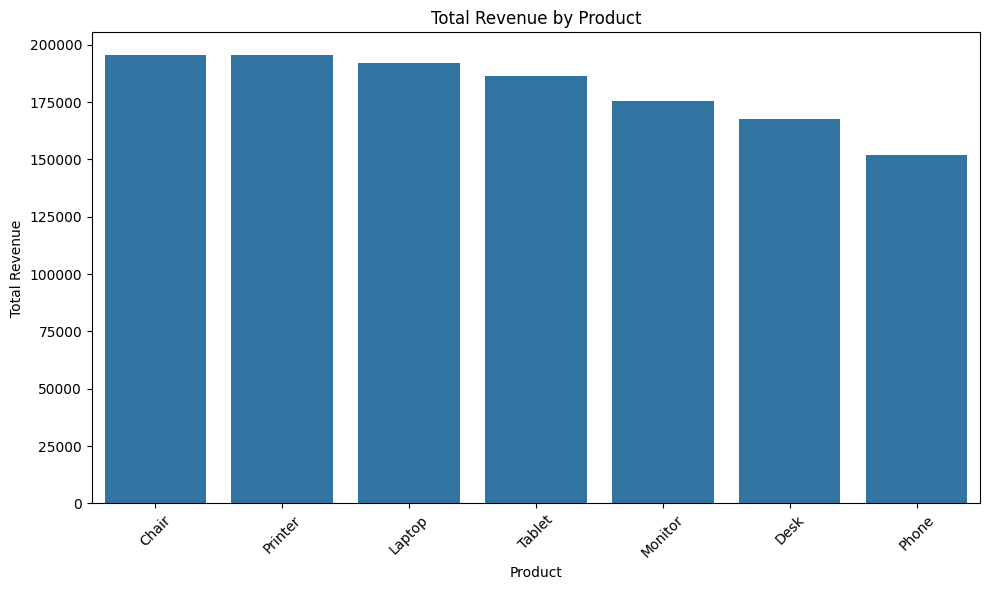

In [20]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=product_summary,
    x="Product",
    y="total_revenue"
)

plt.title("Total Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

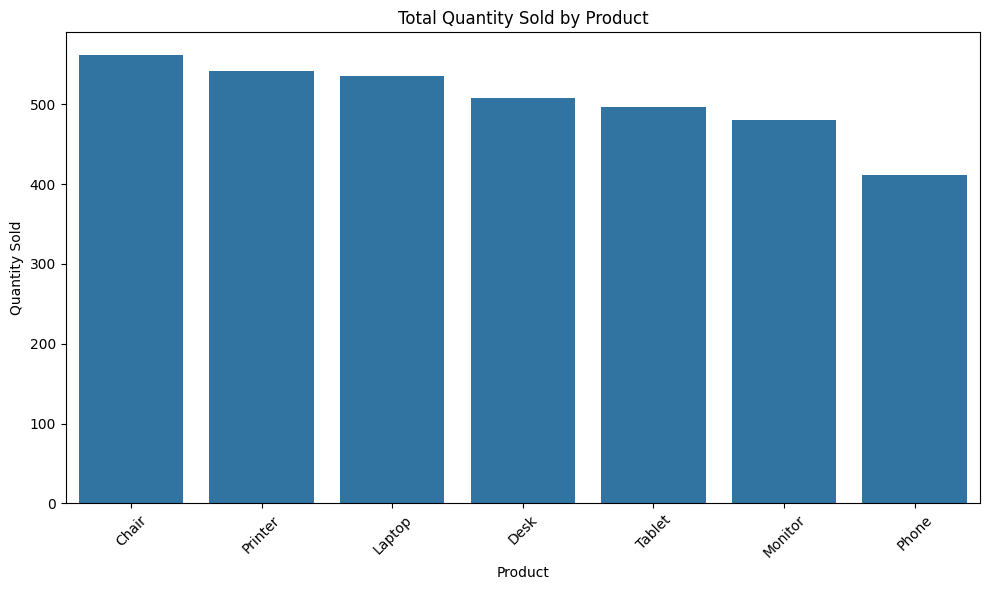

In [21]:
quantity_summary = product_summary.sort_values(
    "total_quantity",
    ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=quantity_summary,
    x="Product",
    y="total_quantity"
)

plt.title("Total Quantity Sold by Product")
plt.xlabel("Product")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [22]:
status_summary = (
    Project_Cleaning.groupby("OrderStatus")["TotalPrice"]
      .agg(["sum", "count", "mean"])
      .sort_values("sum", ascending=False)
)

status_summary

,sum,count,mean
OrderStatus,,,
Cancelled,276396.21,250,1105.584840
Pending,256328.15,237,1081.553376
Shipped,246159.58,235,1047.487574
Returned,243277.70,247,984.929960
Delivered,242600.32,231,1050.217835


In [23]:
Project_Cleaning["PaymentMethod"].value_counts()

,count
PaymentMethod,
Online,258
Cash,246
Credit Card,234
Debit Card,232
Gift Card,230


In [24]:
Project_Cleaning["ReferralSource"].value_counts()

,count
ReferralSource,
Instagram,259
Email,250
Google,241
Facebook,228
Referral,222


In [25]:
pd.crosstab(
    Project_Cleaning["OrderStatus"],
    Project_Cleaning["CouponCode"].isna(),
    margins=True
)

CouponCode,False,True,All
OrderStatus,,,
Cancelled,192,58,250
Delivered,179,52,231
Pending,178,59,237
Returned,171,76,247
Shipped,171,64,235
All,891,309,1200
